In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 15s 0us/step


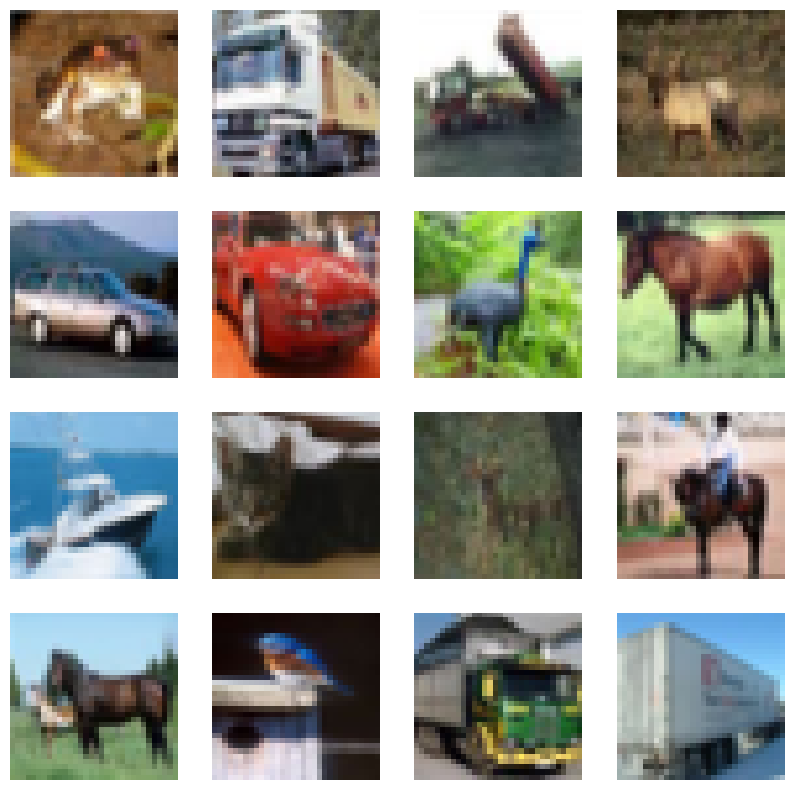

In [2]:
# Load CIFAR-10 dataset for training images
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Normalize the pixel values for augmentation
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Display a sample of the training images
plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.imshow(x_train[i])
    plt.axis('off')

plt.show()

In [3]:
from PIL import Image, ImageDraw

# Create a blank white image
image = Image.new('RGB', (224, 224), color=(255, 255, 255))

# Draw a red square
draw = ImageDraw.Draw(image)
draw.rectangle([(50, 50), (174, 174)], fill=(255, 0, 0))

# Save the image
image.save('sample.jpg')

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator,
    load_img,
    img_to_array
)

# Load a sample image
img_path = 'sample.jpg'
img = load_img(img_path)

x = img_to_array(img)
x = np.expand_dims(x, axis=0)

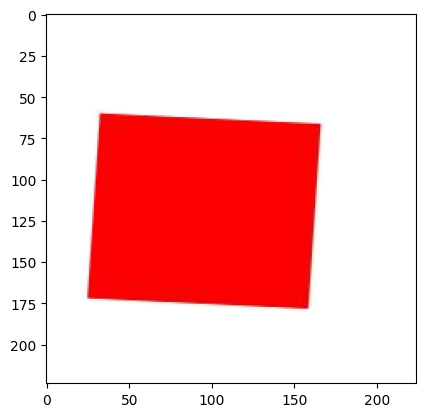

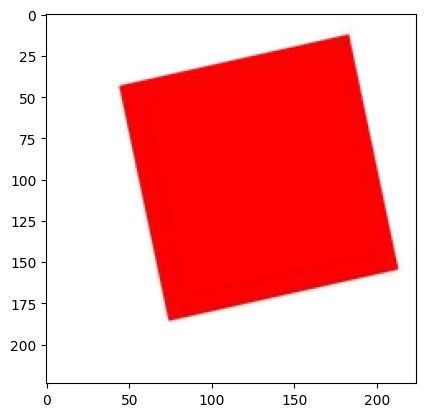

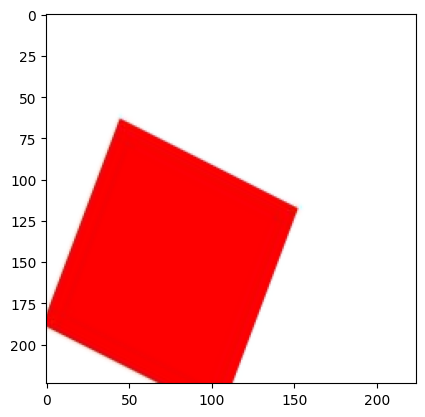

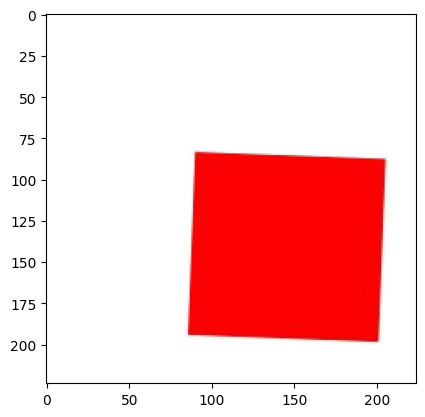

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator,
    load_img,
    img_to_array
)

# Load the sample image
img_path = 'sample.jpg'
img = load_img(img_path)
x = img_to_array(img)
x = np.expand_dims(x, axis=0)

# Create an instance of ImageDataGenerator
datagen = ImageDataGenerator(
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Generate batches of augmented images
i = 0

for batch in datagen.flow(x, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(batch[0].astype('uint8'))

    i += 1

    if i % 4 == 0:
        break

plt.show()

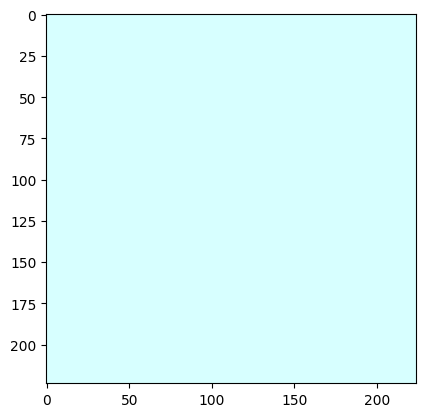

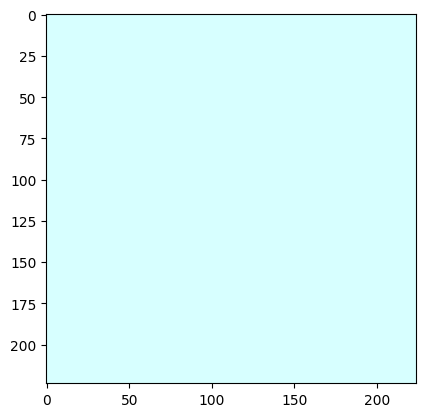

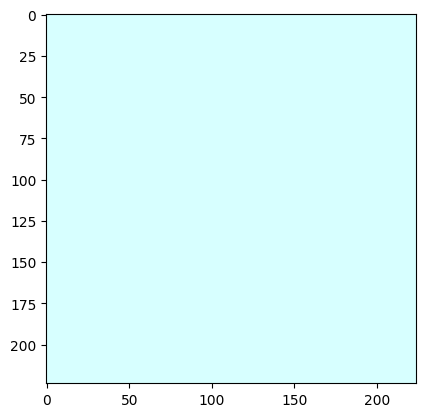

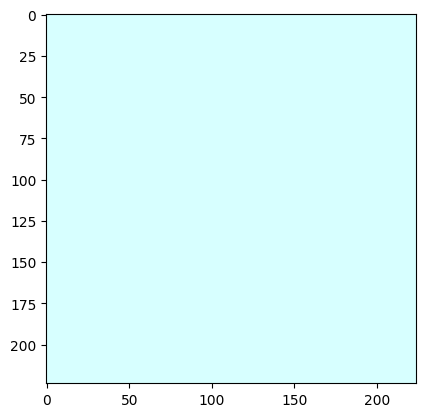

In [7]:
# Create an instance of ImageDataGenerator with normalization options
datagen = ImageDataGenerator(
    featurewise_center=True,
    featurewise_std_normalization=True,
    samplewise_center=True,
    samplewise_std_normalization=True
)

# Load the sample image again and fit the generator
datagen.fit(x)

# Generate batches of normalized images
i = 0

for batch in datagen.flow(x, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(batch[0].astype('uint8'))

    i += 1

    if i % 4 == 0:
        break

plt.show()

# Exercises

In [8]:
!wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/RgP3JFNtPTZA34UmG3KZaA/sample-images.zip

--2026-11-22 07:12:53--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/RgP3JFNtPTZA34UmG3KZaA/sample-images.zip
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14868 (15K) [application/zip]
Saving to: ‘sample-images.zip’

sample-images.zip   100%[===================>]  14.52K  --.-KB/s    in 0s      

2026-11-22 07:12:53 (159 MB/s) - ‘sample-images.zip’ saved [14868/14868]



In [9]:
!unzip sample-images.zip

Archive:  sample-images.zip
   creating: sample_images/
  inflating: sample_images/training_images1.jpg  
  inflating: sample_images/training_images2.jpg  
  inflating: sample_images/training_images3.jpg  


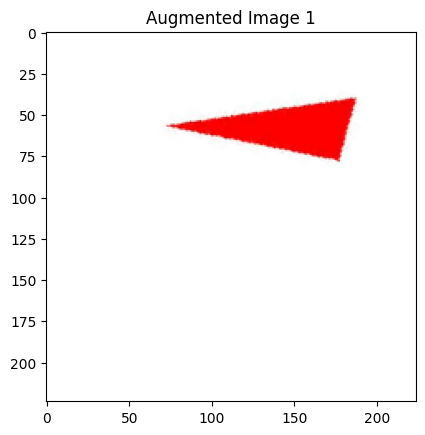

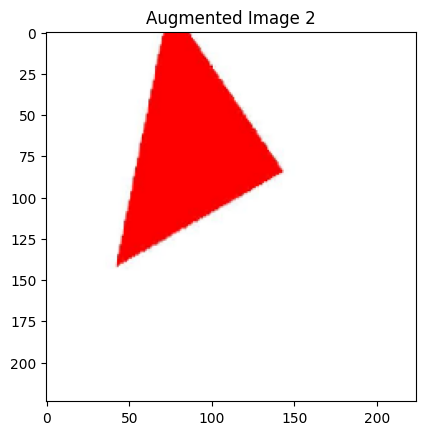

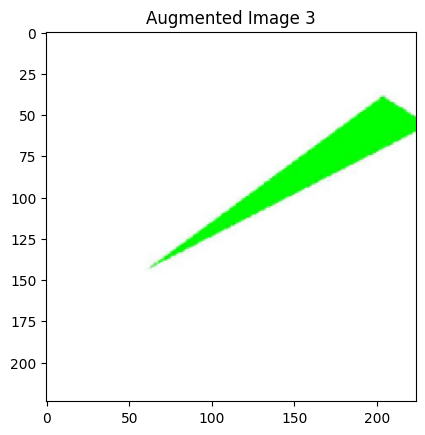

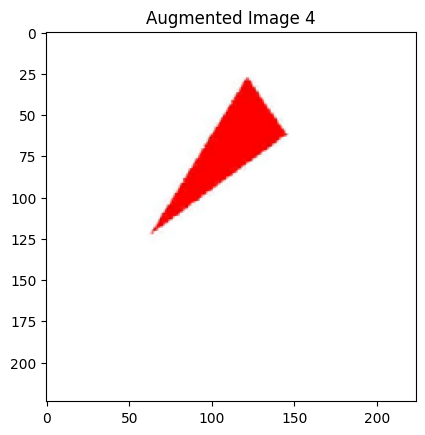

In [10]:
from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator,
    load_img,
    img_to_array,
    array_to_img
)

import matplotlib.pyplot as plt
import numpy as np

# Define the augmentation parameters
datagen = ImageDataGenerator(
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Load and preprocess the dataset
image_paths = [
    'sample_images/training_images1.jpg',
    'sample_images/training_images2.jpg',
    'sample_images/training_images3.jpg'
]

training_images = []

for image_path in image_paths:
    img = load_img(image_path, target_size=(224, 224))
    img_array = img_to_array(img)
    training_images.append(img_array)

training_images = np.array(training_images)

# Generate and visualize augmented images
i = 0

for batch in datagen.flow(training_images, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(array_to_img(batch[0]))
    plt.title(f'Augmented Image {i + 1}')

    i += 1

    if i % 4 == 0:
        break

plt.show()

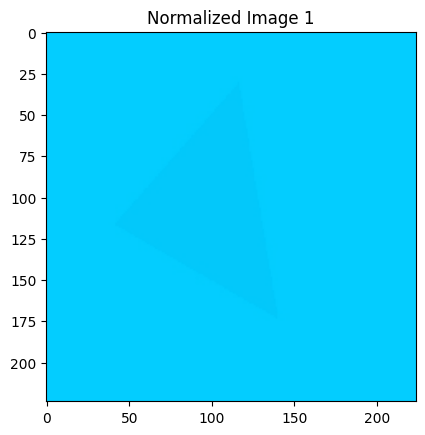

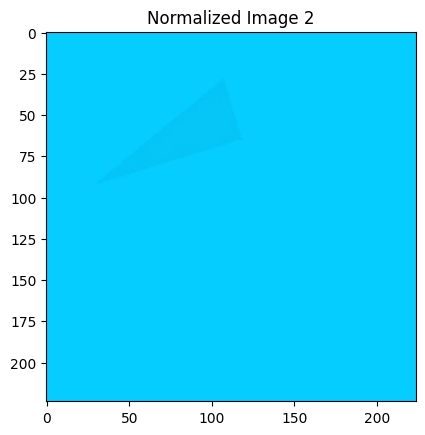

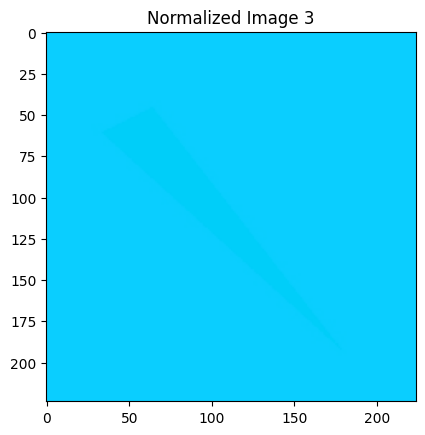

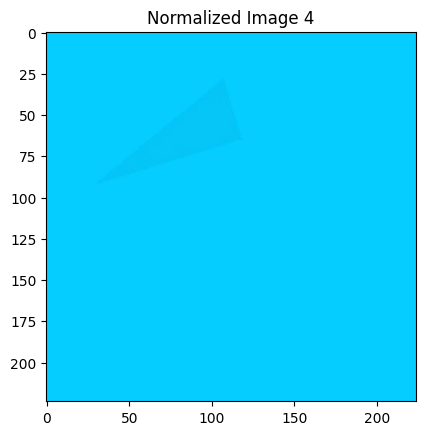

In [11]:
# Create an instance of ImageDataGenerator with normalization options
datagen = ImageDataGenerator(
    featurewise_center=True,
    featurewise_std_normalization=True,
    samplewise_center=True,
    samplewise_std_normalization=True
)

# Fit the ImageDataGenerator to the dataset
datagen.fit(training_images)

# Generate and visualize normalized images
i = 0

for batch in datagen.flow(training_images, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(array_to_img(batch[0]))
    plt.title(f'Normalized Image {i + 1}')

    i += 1

    if i % 4 == 0:
        break

plt.show()

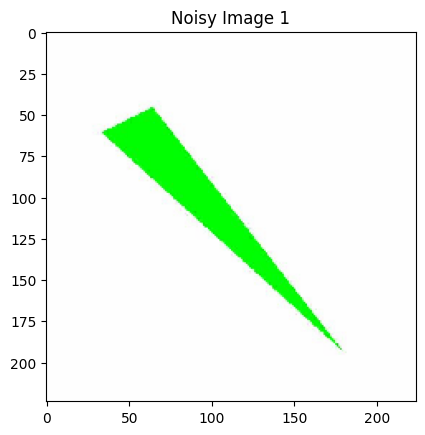

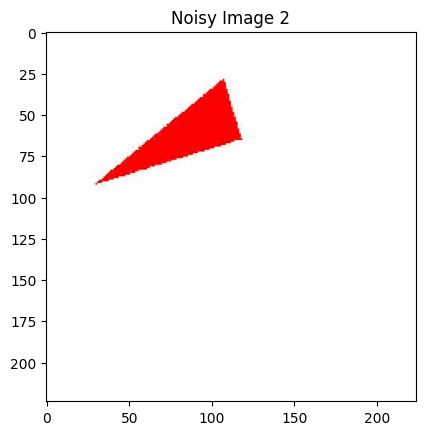

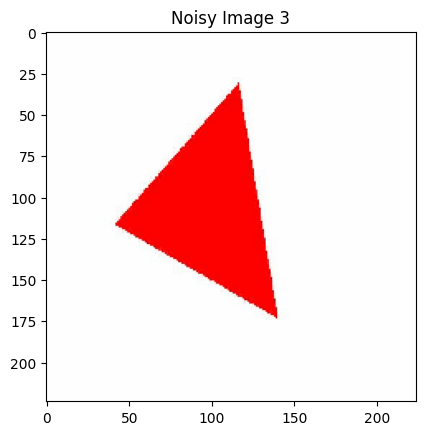

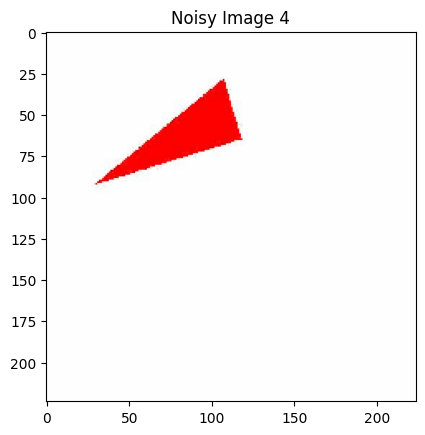

In [12]:
# Define a custom augmentation function to add random noise
def add_random_noise(image):
    noise = np.random.normal(0, 0.1, image.shape)
    return image + noise

# Create an instance of ImageDataGenerator with custom augmentation
datagen = ImageDataGenerator(
    preprocessing_function=add_random_noise
)

# Generate and visualize augmented images
i = 0

for batch in datagen.flow(training_images, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(array_to_img(batch[0]))
    plt.title(f'Noisy Image {i + 1}')

    i += 1

    if i % 4 == 0:
        break

plt.show()